In [1]:
# imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
import sqlite3

from itertools import product
from sklearn.linear_model import LinearRegression

# set up rng seed for reproducibility
rng = np.random.default_rng(seed=9481)


In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 100


# Clean genome metatdata
- Impute missing completeness data
- Simplify dataframe and save as `data/genome-metadata.csv`

In [3]:
# read in genome metadata

metadata_path = Path('../data/inputs/pro-genomes.csv')
genome_df = pd.read_csv(metadata_path)

genome_df

,Genome_Name,Genus,Clade,Sequencing_Status,Study_Name,Sample_Name,IMG_Genome_ID,Analysis_Project_Type,NCBI_Taxon_ID,NCBI_Biosample_Accession,NCBI_GenBank_ID,Depth,Latitude,Longitude,Genome_Size,Gene_Count,Completeness,Contamination,Path,GenomeAlias
0,AC-669-I9,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 I9 (contaminat...,2626541507,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1964467,2686,65.91,7.22,data/0-inputs/genomes/2626541507,ProchlorococcusAC669I9
1,AC-669-J22,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 J22 (contamina...,2626541512,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1826776,2523,65.28,6.84,data/0-inputs/genomes/2626541512,ProchlorococcusAC669J22
2,AC-669-O11,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 O11 (contamina...,2626541532,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1671148,2032,63.19,1.14,data/0-inputs/genomes/2626541532,ProchlorococcusAC669O11
3,AC-669-K21,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 K21 (contamina...,2626541518,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1597402,1953,57.31,3.30,data/0-inputs/genomes/2626541518,ProchlorococcusAC669K21
4,AC-669-K20,Prochlorococcus,AMZ-I,Permanent Draft,Microbial Oceanography of picocyanobacteria in...,Prochlorococcus sp. SCGC AC-669 K20 (contamina...,2626541517,Single Cell Analysis (screened),159733,NaN,NaN,53.0,-20.351667,-70.80,1706781,2490,55.87,3.13,data/0-inputs/genomes/2626541517,ProchlorococcusAC669K20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1101,MIT1223,Prochlorococcus,LLVIII,Finished,ProPortal-Culture-Genomes,Prochlorococcus sp. MIT1223,2681813568,Genome Analysis (Isolate),1220,NaN,NaN,175.0,22.750000,-158.00,1795922,1991,100.00,0.05,data/0-inputs/genomes/2681813568,ProchlorococcusMIT1223
1102,AG-402-N21,Prochlorococcus,LLVIII,Draft,HOT-BATS-SingleCells,Prochlorococcus sp. AG-402-N21 (Screened),2667527276,Single Cell Analysis (screened),2162096,SAMN08886333,QCIW00000000,NaN,22.750000,-158.00,1364872,1545,76.19,0.10,data/0-inputs/genomes/2667527276,ProchlorococcusAG402N21
1103,AG-409-P19,Prochlorococcus,LLVIII,Draft,bioGEOTRACES-SingleCells,Prochlorococcus sp. AG-409-P19,2716884399,Single Cell Analysis (unscreened),2162277,SAMN08886377,QCKO00000000,NaN,9.550000,-50.47,1164213,1300,67.11,0.32,data/0-inputs/genomes/2716884399,ProchlorococcusAG409P19
1104,AG-409-D09,Prochlorococcus,LLVIII,Draft,bioGEOTRACES-SingleCells,Prochlorococcus sp. AG-409-D09,2716884266,Single Cell Analysis (unscreened),2162204,SAMN08886353,QCJQ00000000,NaN,9.550000,-50.47,1218575,1438,64.91,0.00,data/0-inputs/genomes/2716884266,ProchlorococcusAG409D09


,Genome_Name,Genus,Clade,Sequencing_Status,Study_Name,Sample_Name,IMG_Genome_ID,Analysis_Project_Type,NCBI_Taxon_ID,NCBI_Biosample_Accession,...,Depth,Latitude,Longitude,Genome_Size,Gene_Count,Completeness,Contamination,Path,GenomeAlias,Imputed_Completeness
123,AG-321-O21,Prochlorococcus,HLI,Draft,BiGRAPA-SouthPacific-SingleCells,Uncultured Prochlorococcus sp. AG-321-O21,2716884648,Single Cell Analysis (unscreened),1218,SAMN08886018,...,NaN,-23.46,-88.77,99003,123,10.148355,NaN,data/0-inputs/genomes/2716884648,ProchlorococcusAG321O21,True
124,AG-343-G04,Prochlorococcus,HLI,Permanent Draft,Charting the complexity of the marine microbio...,Synechococcaceae cyanobacterium AG-343-G04,8135953660,Single Cell Analysis (unscreened),1665021,SAMEA6078190,...,NaN,NaN,NaN,91721,123,9.890947,NaN,data/0-inputs/genomes/8135953660,ProchlorococcusAG343G04,True
271,AG-422-G21,Prochlorococcus,HLII,Permanent Draft,Charting the complexity of the marine microbio...,Prochlorococcus sp. AG-422-G21,8026898962,Single Cell Analysis (unscreened),159733,SAMEA6076281,...,NaN,NaN,NaN,1334801,1674,73.403590,NaN,data/0-inputs/genomes/8026898962,ProchlorococcusAG422G21,True
272,AG-430-N10,Prochlorococcus,HLII,Permanent Draft,Charting the complexity of the marine microbio...,Synechococcaceae cyanobacterium AG-430-N10,8135953788,Single Cell Analysis (unscreened),1665021,SAMEA6079953,...,NaN,NaN,NaN,92575,130,10.009465,NaN,data/0-inputs/genomes/8135953788,ProchlorococcusAG430N10,True
843,AG-333-B07,Prochlorococcus,LLI,Permanent Draft,Charting the complexity of the marine microbio...,Prochlorococcus sp. AG-333-B07,8135953923,Single Cell Analysis (unscreened),159733,SAMEA6077524,...,NaN,NaN,NaN,91609,125,9.912225,NaN,data/0-inputs/genomes/8135953923,ProchlorococcusAG333B07,True
966,MIT1304,Prochlorococcus,LLII-LLIII,Permanent Draft,ProPortal-Culture-Genomes,Prochlorococcus sp. MIT1304,2681813571,Genome Analysis (Isolate),1220,NaN,...,150.0,22.75,-158.00,1762159,1952,92.018079,NaN,data/0-inputs/genomes/2681813571,ProchlorococcusMIT1304,True
1006,MIT1205,Prochlorococcus,LLIV,Permanent Draft,ProPortal-Culture-Genomes,Prochlorococcus sp. MIT1205,2681813566,Genome Analysis (Isolate),1220,NaN,...,175.0,22.75,-158.00,2527266,2674,100.000000,NaN,data/0-inputs/genomes/2681813566,ProchlorococcusMIT1205,True


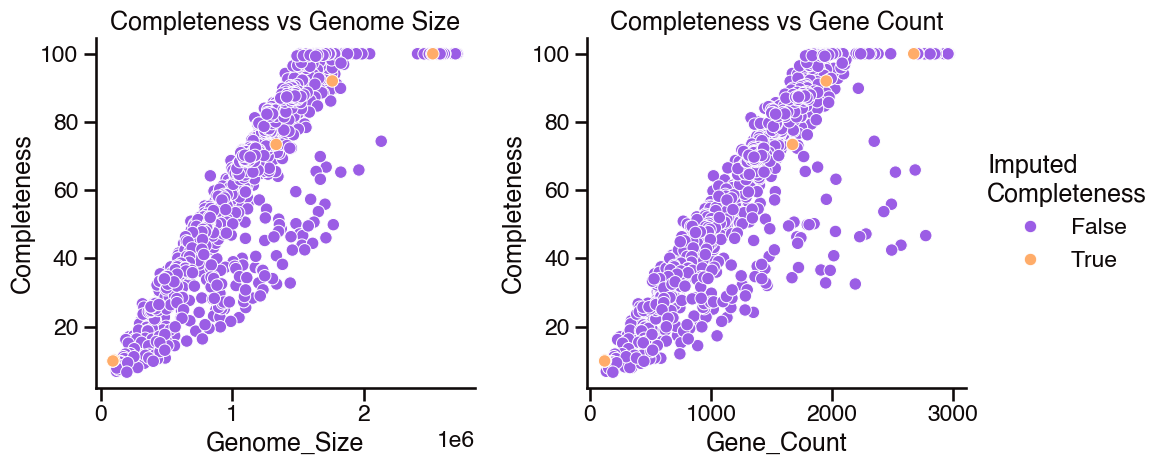

In [4]:
# impute missing completeness values with linear regression based on genome size and gene count

complete_df = genome_df.dropna(subset=['Completeness']) 
X = complete_df[['Genome_Size', 'Gene_Count']]
y = complete_df['Completeness']
model = LinearRegression()
model.fit(X, y)
missing_df = genome_df[genome_df['Completeness'].isna()]
X_missing = missing_df[['Genome_Size', 'Gene_Count']]
imputed_completeness = model.predict(X_missing)

# clip imputed values to valid range [0, 100]
imputed_completeness = np.clip(imputed_completeness, 0, 100)

# add imputed values back to genome_df, keeping track of which values were imputed
genome_df['Imputed_Completeness'] = genome_df['Completeness'].isna()
genome_df.loc[genome_df['Completeness'].isna(), 'Completeness'] = imputed_completeness
display(genome_df.loc[genome_df['Imputed_Completeness']])

# plot completeness vs genome size and vs gene count with imputed values highlighted
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) 
sns.scatterplot(
    data=genome_df.sort_values(by='Imputed_Completeness'),
    x='Genome_Size',
    y='Completeness',
    hue='Imputed_Completeness',
    ax=axes[0], 
    legend=False
)
axes[0].set_title('Completeness vs Genome Size')
sns.scatterplot(
    data=genome_df.sort_values(by='Imputed_Completeness'),
    x='Gene_Count',
    y='Completeness',
    hue='Imputed_Completeness',
    ax=axes[1], 
    legend=True
)
axes[1].set_title('Completeness vs Gene Count')
axes[1].legend(title='Imputed\nCompleteness', 
               loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

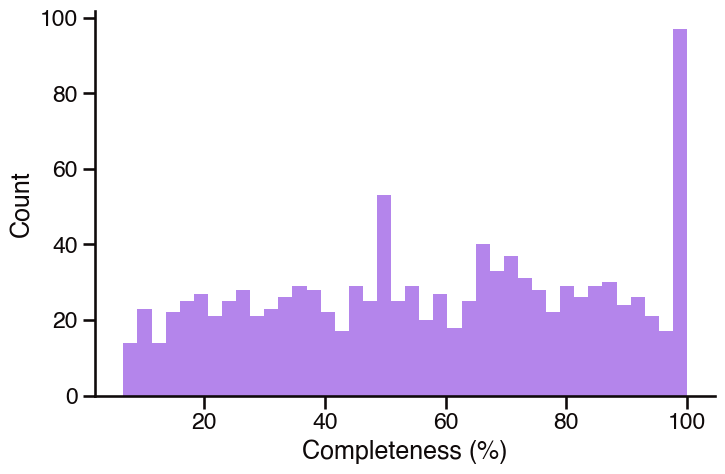

Total number of genomes: 1106
Number of finished genomes (Status = Finished): 65
Number of draft genomes (Status = Draft): 1041
Number of genomes with completeness >=99%: 92
Number of genomes with completeness >=95%: 119
Number of genomes with completeness <60%: 570


In [5]:
# generate histogram of completeness values for publication

plt.figure(figsize=(8, 5))
sns.histplot(genome_df['Completeness'], bins=40, kde=False, color=palette[0])
# plt.title('Distribution of Genome Completeness')
plt.xlabel('Completeness (%)')
plt.ylabel('Count')
plt.show()

# count number of finished genomes versus draft genomes
print(f"Total number of genomes: {genome_df.shape[0]}")
print(f"Number of finished genomes (Status = Finished): {genome_df[genome_df['Sequencing_Status'] == 'Finished'].shape[0]}")
print(f"Number of draft genomes (Status = Draft): {genome_df[genome_df['Sequencing_Status'] != 'Finished'].shape[0]}")
print(f"Number of genomes with completeness >=99%: {genome_df[genome_df['Completeness'] >= 99].shape[0]}")
print(f"Number of genomes with completeness >=95%: {genome_df[(genome_df['Completeness'] >= 95)].shape[0]}")
print(f"Number of genomes with completeness <60%: {genome_df[(genome_df['Completeness'] < 60)].shape[0]}")


In [6]:
# save and simplify metadata for downstream use

metadata_output_path = Path('../data/pro_pangenome_metadata.csv')

# simplify metadata
metadata_df = genome_df[[
    'GenomeAlias', 'Clade', 'Completeness', 
    'Sequencing_Status', 'Imputed_Completeness']]
metadata_df = metadata_df.rename(columns={
    'GenomeAlias': 'genome',
    'Clade': 'clade',
    'Completeness': 'completeness',
    'Sequencing_Status': 'sequencing_status',
    'Imputed_Completeness': 'imputed_completeness'
})
metadata_df['complete'] = metadata_df['sequencing_status'] == 'Finished'

# save metadata to CSV
metadata_df.to_csv(metadata_output_path, index=False)

metadata_df

,genome,clade,completeness,sequencing_status,imputed_completeness,complete
0,ProchlorococcusAC669I9,AMZ-I,65.91,Permanent Draft,False,False
1,ProchlorococcusAC669J22,AMZ-I,65.28,Permanent Draft,False,False
2,ProchlorococcusAC669O11,AMZ-I,63.19,Permanent Draft,False,False
3,ProchlorococcusAC669K21,AMZ-I,57.31,Permanent Draft,False,False
4,ProchlorococcusAC669K20,AMZ-I,55.87,Permanent Draft,False,False
...,...,...,...,...,...,...
1101,ProchlorococcusMIT1223,LLVIII,100.00,Finished,False,True
1102,ProchlorococcusAG402N21,LLVIII,76.19,Draft,False,False
1103,ProchlorococcusAG409P19,LLVIII,67.11,Draft,False,False
1104,ProchlorococcusAG409D09,LLVIII,64.91,Draft,False,False


# Clean count data
- Build matrix of gene family count data
- Save incomplete and complete datasets separately

In [7]:
# generate gene family count matrix from anvi'o pangenome database

db_path = Path('../data/inputs/propan-PAN.db')

query = '''
SELECT
  gene_caller_id, 
  gene_cluster_id,
  genome_name,
  COUNT(*) AS occurrences
FROM gene_clusters
GROUP BY gene_caller_id, gene_cluster_id, genome_name
'''.strip()

with sqlite3.connect(db_path) as conn:
    long_df = pd.read_sql_query(query, conn)

gc_count_df = long_df.pivot_table(
    index='gene_cluster_id',
    columns='genome_name',
    values='occurrences',
    aggfunc='sum',
    fill_value=0,
)

gc_count_df

genome_name,ProchlorococcusAC669E6,ProchlorococcusAC669I11,ProchlorococcusAC669I15,ProchlorococcusAC669I23,ProchlorococcusAC669I4,ProchlorococcusAC669I9,ProchlorococcusAC669J11,ProchlorococcusAC669J17,ProchlorococcusAC669J2,ProchlorococcusAC669J20,...,ProchlorococcusW10,ProchlorococcusW11,ProchlorococcusW12,ProchlorococcusW2,ProchlorococcusW3,ProchlorococcusW4,ProchlorococcusW6,ProchlorococcusW7,ProchlorococcusW8,ProchlorococcusW9
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,0,0,0,0,0,0,0,3,0,0,...,4,2,11,11,2,13,0,4,0,1
GC_00000002,1,1,2,4,5,4,1,2,1,1,...,1,2,0,3,0,2,2,2,2,1
GC_00000003,4,1,2,3,1,5,2,2,3,1,...,3,3,0,3,0,3,0,1,1,6
GC_00000004,2,1,2,2,3,2,3,1,17,0,...,1,0,1,1,0,0,1,1,0,1
GC_00000005,3,1,5,9,6,6,4,6,21,22,...,3,3,0,1,0,0,0,3,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
# build presence-absence matrix from count matrix

gc_pa_df = gc_count_df.copy()
gc_pa_df[gc_pa_df > 0] = 1
gc_pa_df

genome_name,ProchlorococcusAC669E6,ProchlorococcusAC669I11,ProchlorococcusAC669I15,ProchlorococcusAC669I23,ProchlorococcusAC669I4,ProchlorococcusAC669I9,ProchlorococcusAC669J11,ProchlorococcusAC669J17,ProchlorococcusAC669J2,ProchlorococcusAC669J20,...,ProchlorococcusW10,ProchlorococcusW11,ProchlorococcusW12,ProchlorococcusW2,ProchlorococcusW3,ProchlorococcusW4,ProchlorococcusW6,ProchlorococcusW7,ProchlorococcusW8,ProchlorococcusW9
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,0,0,0,0,0,0,0,1,0,0,...,1,1,1,1,1,1,0,1,0,1
GC_00000002,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,0,1,1,1,1,1
GC_00000003,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,0,1,0,1,1,1
GC_00000004,1,1,1,1,1,1,1,1,1,0,...,1,0,1,1,0,0,1,1,0,1
GC_00000005,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
# save full pangenome count and presence-absence matrices for downstream use

count_output_path = Path('../data/pro_pangenome_count_data.csv')
pa_output_path = Path('../data/pro_pangenome_presence_absence_data.csv')

gc_count_df.to_csv(count_output_path, index=True)
gc_pa_df.to_csv(pa_output_path, index=True)

## Subsets
Separate out subsets of data for downstream use
- complete vs incomplete genomes
- complete vs incomplete genomes with proportional clade representation

In [10]:
# separate out complete and incomplete genome subsets

complete_genomes = metadata_df[metadata_df['complete']]['genome']
incomplete_genomes = metadata_df[~metadata_df['complete']]['genome']
print(f'Complete genomes: {len(complete_genomes)}')
print(f'Incomplete genomes: {len(incomplete_genomes)}')

# make sure output directory exists
subsets_dir = Path('../data/subsets')
subsets_dir.mkdir(parents=True, exist_ok=True)

# separate count and presence-absence matrices for complete and incomplete genomes
gc_count_complete_df = gc_count_df[complete_genomes]
gc_count_incomplete_df = gc_count_df[incomplete_genomes]
gc_pa_complete_df = gc_pa_df[complete_genomes]
gc_pa_incomplete_df = gc_pa_df[incomplete_genomes]

# save subsets to CSV
gc_count_complete_df.to_csv(subsets_dir / 'pro_count_data_complete.csv', index=True)
gc_count_incomplete_df.to_csv(subsets_dir / 'pro_count_data_incomplete.csv', index=True)
gc_pa_complete_df.to_csv(subsets_dir / 'pro_presence_absence_data_complete.csv', index=True)
gc_pa_incomplete_df.to_csv(subsets_dir / 'pro_presence_absence_data_incomplete.csv', index=True)

gc_count_complete_df

Complete genomes: 65
Incomplete genomes: 1041


genome_name,ProchlorococcusDV,ProchlorococcusMIT9515,ProchlorococcusMED1,ProchlorococcusMED4,ProchlorococcusMIT9123,ProchlorococcusMIT0604,ProchlorococcusMIT9302,ProchlorococcusMIT9116,ProchlorococcusMIT9314,ProchlorococcusMIT9201,...,ProchlorococcusMIT1201,ProchlorococcusMIT1306,ProchlorococcusMIT1342,ProchlorococcusMIT1303,ProchlorococcusMIT1323,ProchlorococcusMIT1320,ProchlorococcusMIT1307,ProchlorococcusMIT1341,ProchlorococcusMIT1300,ProchlorococcusMIT1223
gene_cluster_id,,,,,,,,,,,,,,,,,,,,,
GC_00000001,13,12,13,13,7,5,12,7,10,10,...,4,4,4,3,4,4,5,4,7,4
GC_00000002,3,3,3,3,3,3,3,3,3,3,...,3,3,4,3,3,3,3,3,3,3
GC_00000003,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
GC_00000004,1,2,1,1,2,2,2,2,2,2,...,2,2,2,2,2,2,8,7,6,7
GC_00000005,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GC_00052854,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052855,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GC_00052856,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
# subsample complete and incomplete genomes to create class-balanced datasets for testing
# (i.e. complete and incomplete genomes will have the same clade composition)

# count number of complete and incomplete genomes per clade in full set of Pro genomes
clade_count_df = metadata_df.groupby('clade').complete.value_counts().unstack(fill_value=0)
clade_count_df = clade_count_df.rename(
    columns={True: 'n_complete_total', False: 'n_incomplete_total'})[
    ['n_complete_total', 'n_incomplete_total']]
clade_count_df.columns.name = None
clade_count_df.index.name = None

# calculate number of genomes to downsample from each clade for complete and incomplete subsets
factor = 1
clade_count_df['n_complete_subset'] = clade_count_df['n_complete_total'].clip(upper=clade_count_df['n_incomplete_total'])
clade_count_df['n_incomplete_subset'] = clade_count_df['n_incomplete_total'].clip(upper=clade_count_df['n_complete_total'] * factor)
clade_count_df['n_complete_subset'] = clade_count_df['n_complete_subset'].clip(upper=clade_count_df['n_incomplete_subset'] // factor)
clade_count_df['n_incomplete_subset'] = clade_count_df['n_incomplete_total'].clip(upper=clade_count_df['n_complete_subset'] * factor)
clade_count_df['frac_subset'] = clade_count_df['n_complete_subset'] / clade_count_df['n_complete_subset'].sum()

# randomly select genomes for complete and incomplete subsets based on calculated numbers
complete_subset_genomes = []
incomplete_subset_genomes = []
for clade, row in clade_count_df.iterrows():
    complete_genomes_clade = metadata_df[
        (metadata_df['clade'] == clade) & (metadata_df['complete'])]['genome']
    incomplete_genomes_clade = metadata_df[
        (metadata_df['clade'] == clade) & (~metadata_df['complete'])]['genome']
    complete_subset_genomes.extend(
        rng.choice(
            complete_genomes_clade, size=row['n_complete_subset'].astype(int), replace=False))
    incomplete_subset_genomes.extend(
        rng.choice(
            incomplete_genomes_clade, size=row['n_incomplete_subset'].astype(int), replace=False))

print(f'Total genomes sampled for complete subset: {clade_count_df["n_complete_subset"].sum()}')
print(f'Total genomes sampled for incomplete subset: {clade_count_df["n_incomplete_subset"].sum()}')
print(f'Overall total genomes sampled: {clade_count_df[["n_complete_subset", "n_incomplete_subset"]].sum().sum()}')
print(f'Overall total clades sampled: {clade_count_df[["n_complete_subset", "n_incomplete_subset"]].gt(0).any(axis=1).sum()}')

clade_count_df

Total genomes sampled for complete subset: 60
Total genomes sampled for incomplete subset: 60
Overall total genomes sampled: 120
Overall total clades sampled: 7


,n_complete_total,n_incomplete_total,n_complete_subset,n_incomplete_subset,frac_subset
AMZ-I,0,48,0,0,0.000000
AMZ-II,0,32,0,0,0.000000
AMZ-III,0,43,0,0,0.000000
HLI,4,144,4,4,0.066667
HLII,17,502,17,17,0.283333
HLII-HLVI,0,2,0,0,0.000000
HLIII,0,9,0,0,0.000000
HLIV,0,30,0,0,0.000000
HLVI,0,12,0,0,0.000000
LLI,13,110,13,13,0.216667


In [12]:
# pull out and save the count and presence-absence matrices for the complete and incomplete subsets

gc_count_complete_clade_balanced_df = gc_count_df[complete_subset_genomes]
gc_count_incomplete_clade_balanced_df = gc_count_df[incomplete_subset_genomes]
gc_pa_complete_clade_balanced_df = gc_pa_df[complete_subset_genomes]
gc_pa_incomplete_clade_balanced_df = gc_pa_df[incomplete_subset_genomes]

gc_count_complete_clade_balanced_df.to_csv(subsets_dir / 'pro_count_data_complete_clade_balanced.csv', index=True)
gc_count_incomplete_clade_balanced_df.to_csv(subsets_dir / 'pro_count_data_incomplete_clade_balanced.csv', index=True)
gc_pa_complete_clade_balanced_df.to_csv(subsets_dir / 'pro_presence_absence_data_complete_clade_balanced.csv', index=True)
gc_pa_incomplete_clade_balanced_df.to_csv(subsets_dir / 'pro_presence_absence_data_incomplete_clade_balanced.csv', index=True)

# show saved files in directory
for f in subsets_dir.iterdir():
    print(f'✅ {f.name}')

✅ pro_presence_absence_data_incomplete.csv
✅ pro_presence_absence_data_complete_clade_balanced.csv
✅ pro_presence_absence_data_complete.csv
✅ pro_count_data_incomplete_clade_balanced.csv
✅ pro_count_data_incomplete.csv
✅ pro_presence_absence_data_incomplete_clade_balanced.csv
✅ pro_count_data_complete.csv
✅ pro_count_data_complete_clade_balanced.csv
